# MAI101 Assignment 1: Vehicle Selling Price Prediction Report

**Objective:** Build a regression model to predict used vehicle selling prices based on key vehicle attributes while avoiding data leakage.

### Data Loading & Inspection
Importing the required libraries, uploading the raw dataset (`MAI101_Assignment1_used_vehicle_data.csv`), and previewing the first few rows to verify the dataset structure.


In [1]:
import pandas as pd
import numpy as np
from google.colab import files

# Upload raw dataset file
uploaded_files = files.upload()

# Load into DataFrame
car_data = pd.read_csv("MAI101_Assignment1_used_vehicle_data.csv")
car_data.head()

Saving MAI101_Assignment1_used_vehicle_data.csv to MAI101_Assignment1_used_vehicle_data (2).csv


,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
0,Mercedes-Benz,GLA,2010,193254.0,1.8,Gasoline,Automatic,Sedan,AWD,4.0,5.0,0.0,2.0,Red,40.0,0.0,7.0,39257.66
1,Nissan,Frontier,2021,58800.0,5.7,Gasoline,Automatic,SUV,FWD,4.0,5.0,1.0,3.0,Black,71.0,0.0,2.0,42237.72
2,Hyundai,Palisade,2017,127591.0,2.0,Hybrid,Dual-Clutch,SUV,AWD,5.0,6.0,1.0,1.0,Brown,23.0,0.0,7.0,45240.28
3,BMW,X3,2015,170698.0,2.5,Gasoline,Automatic,Sedan,4WD,4.0,7.0,1.0,2.0,Silver,94.0,0.0,9.0,46287.33
4,Honda,Accord,2022,NaN,1.6,Gasoline,Automatic,SUV,AWD,4.0,5.0,1.0,2.0,Grey,44.0,0.0,6.0,54516.51


# 1. Exploratory Data Analysis

### Dataset Structure & Target Distribution
In this section, we analyze the structure, quality, and statistical characteristics of the dataset:

* **Dataset Dimensions & Types**: The raw dataset contains **1,815 rows and 18 columns**, consisting of numerical attributes (`float64`, `int64`) and categorical features (`object`).
* **Missing Data & Errors**: Several features contain missing values, including `KILOMETRES` (36 missing), `ENGINE_SIZE` (54 missing), `FUEL_TYPE`, and `COLOUR`. Summary statistics also reveal unrealistic data entries, such as negative kilometrage (`min: -272,858`), negative listing duration (`min: -119`), and engine sizes of `0.0`.
* **Target Variable Distribution**: The target variable, `SELLING_PRICE`, ranges from **$982.74 to $281,155.00** with a median of **$42,825.34**. The distribution is right-skewed due to extreme luxury vehicle outliers on the high end.
* **Predictor Relationships**: Preliminary analysis indicates that newer model years (`YEAR`) and larger engine sizes (`ENGINE_SIZE`) correlate positively with higher selling prices, whereas higher kilometrage (`KILOMETRES`) and accident history (`ACCIDENTS`) reduce vehicle value.

Dataset shape: (1815, 18)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1815 entries, 0 to 1814
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MAKE             1815 non-null   object 
 1   MODEL            1815 non-null   object 
 2   YEAR             1815 non-null   int64  
 3   KILOMETRES       1779 non-null   float64
 4   ENGINE_SIZE      1761 non-null   float64
 5   FUEL_TYPE        1796 non-null   object 
 6   TRANSMISSION     1788 non-null   object 
 7   BODY_TYPE        1797 non-null   object 
 8   DRIVETRAIN       1770 non-null   object 
 9   DOORS            1797 non-null   float64
 10  SEATS            1797 non-null   float64
 11  ACCIDENTS        1779 non-null   float64
 12  OWNERS           1778 non-null   float64
 13  COLOUR           1761 non-null   object 
 14  LISTING_DAYS     1797 non-null   float64
 15  HAS_WARRANTY     1788 non-null   float64
 16  CONDITION_SCORE  1778 non-null   

,YEAR,KILOMETRES,ENGINE_SIZE,DOORS,SEATS,ACCIDENTS,OWNERS,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
count,1815.000000,1779.000000,1761.000000,1797.000000,1797.000000,1779.000000,1778.000000,1797.000000,1788.000000,1778.000000,1805.000000
mean,2016.458402,127023.460933,2.727882,4.037284,5.609905,0.532884,1.793026,60.435170,0.426734,7.157480,43170.606828
std,4.115250,83708.999429,1.127467,0.773482,1.220998,0.842096,0.874781,35.111814,0.494741,1.979055,16278.174023
min,1992.000000,-272858.000000,0.000000,2.000000,2.000000,0.000000,1.000000,-119.000000,0.000000,0.000000,982.739169
25%,2013.000000,65352.500000,2.000000,4.000000,5.000000,0.000000,1.000000,29.000000,0.000000,6.000000,32776.160000
50%,2016.000000,121216.000000,2.400000,4.000000,5.000000,0.000000,2.000000,61.000000,0.000000,8.000000,42825.340000
75%,2020.000000,180367.500000,3.500000,4.000000,7.000000,1.000000,2.000000,91.000000,1.000000,9.000000,52333.440000
max,2029.000000,956421.000000,6.200000,5.000000,8.000000,3.000000,4.000000,119.000000,1.000000,11.000000,281155.002801


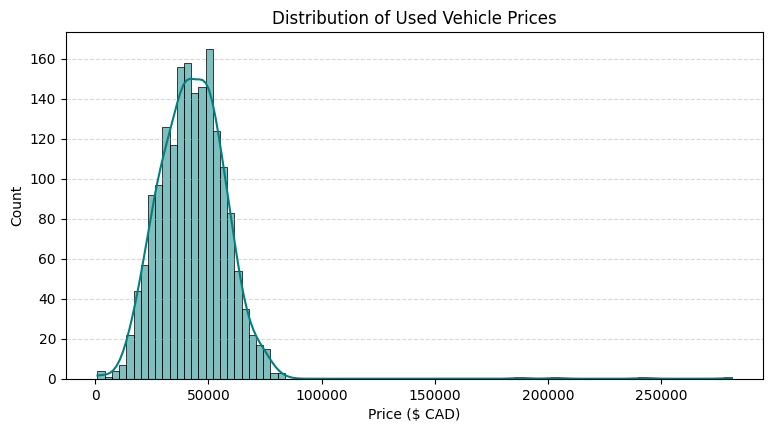

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# checking on dataset size and features
print(f"Dataset shape: {car_data.shape}\n")
car_data.info()

# overview stats for numerical columns
summary_table = car_data.describe()
display(summary_table)

# checking target variable distribution
plt.figure(figsize=(9, 4.5))
sns.histplot(car_data['SELLING_PRICE'], kde=True, color='teal')
plt.title('Distribution of Used Vehicle Prices')
plt.xlabel('Price ($ CAD)')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# 2. Data Preparation

### 2a. Individual Variables
* **LISTING_DAYS**: Dropped this feature entirely to prevent data leakage, as we wouldn't know how long a car takes to sell when estimating its initial price.
* **SELLING_PRICE**: As our target variable, I bounded prices between $3,000 and $120,000 to filter out unrealistic values and extreme luxury outliers.
* **KILOMETRES**: Removed negative kilometrage errors ($\ge 0$) and filled in any missing values using the column median.
* **ENGINE_SIZE**: Filtered out invalid 0.0 engine size entries ($> 0$) and imputed missing values with the median.
* **YEAR**: Restricted vehicle model years to a realistic range (1995–2026) and replaced missing entries with the median.
* **CONDITION_SCORE**: Kept condition ratings within the proper 1–10 scale and filled missing entries using the median.
* **Categorical Features (MAKE, MODEL, FUEL_TYPE, TRANSMISSION, BODY_TYPE, DRIVETRAIN, COLOUR)**: Imputed missing categorical entries using each column's mode (the most frequent value).
* **DOORS, SEATS, ACCIDENTS, OWNERS, HAS_WARRANTY**: Filled missing values using their median and kept them in the dataset as numerical predictors.

In [3]:
# Drop listing duration to prevent target leakage
clean_cars = car_data.drop(columns=['LISTING_DAYS'])

# Filter price outliers and invalid entries across features
clean_cars = clean_cars[
    (clean_cars['SELLING_PRICE'].between(3000, 120000)) &
    (clean_cars['KILOMETRES'] >= 0) &
    (clean_cars['ENGINE_SIZE'] > 0) &
    (clean_cars['CONDITION_SCORE'].between(1, 10)) &
    (clean_cars['YEAR'].between(1995, 2026))
].copy()

# Fill missing numerical values with median
num_cols = clean_cars.select_dtypes(include=[np.number]).columns
for col in num_cols:
    clean_cars[col] = clean_cars[col].fillna(clean_cars[col].median())

# Fill missing categorical values with mode
cat_cols = clean_cars.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    clean_cars[col] = clean_cars[col].fillna(clean_cars[col].mode()[0])

print(f"Cleaned dataset rows: {len(clean_cars)}")

Cleaned dataset rows: 1654


### 2b. Dataset-Level Preparation
* **Predictor & Target Separation**: Separated the dataset by pulling out `SELLING_PRICE` as our target variable (`target_price`) and keeping all other cleaned columns as predictors.
* **Categorical Encoding**: Used `pd.get_dummies(drop_first=True)` to convert categorical attributes into dummy binary variables while dropping the first level to avoid multi-collinearity.
* **Train/Test Split**: Splitting the data into an **80% training set** (1,323 vehicles) and a **20% testing set** (331 vehicles) using `random_state=76` to ensure our model evaluation is repeatable and completely unbiased.

In [4]:
from sklearn.model_selection import train_test_split

# separate predictor features from target variable
predictors = clean_cars.drop(columns=['SELLING_PRICE'])
target_price = clean_cars['SELLING_PRICE']

# convert categorical variables into dummy indicators
model_features = pd.get_dummies(predictors, drop_first=True)

# train / test split
train_features, test_features, train_y, test_y = train_test_split(
    model_features, target_price, test_size=0.2, random_state=76
)

print(f"Training features shape: {train_features.shape}")
print(f"Testing features shape:  {test_features.shape}")

Training features shape: (1323, 273)
Testing features shape:  (331, 273)


# 3. Model

To estimate vehicle selling prices based on our preprocessed features, I built a standard Linear Regression model. The model was trained on the 80% training split (`train_features` and `train_y`) and evaluated using the 20% holdout test set (`test_features` and `test_y`) to ensure an unbiased performance check.

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# build and fit the linear regression model
car_eval_model = LinearRegression()
car_eval_model.fit(train_features, train_y)

# get predictions on test split
preds = car_eval_model.predict(test_features)

# calculate evaluation metrics
mae_score = mean_absolute_error(test_y, preds)
rmse_score = np.sqrt(mean_squared_error(test_y, preds))
r2_val = r2_score(test_y, preds)

# display results
print(f"MAE:  ${mae_score:,.2f}")
print(f"RMSE: ${rmse_score:,.2f}")
print(f"R2:   {r2_val:.4f}")

MAE:  $3,142.74
RMSE: $4,696.32
R2:   0.8707


# 4. Evaluation & Reflection

### Model Performance
I evaluated the Linear Regression model on the 20% holdout test set, and it performed quite well across our key metrics:
- MAE: \$3,142.74 - On average, our price predictions are off by roughly \$3,140.
- RMSE: \$4,696.32 - The higher RMSE relative to MAE indicates that the model gets hit with larger penalties when predicting higher-priced luxury cars.
- R-squared: 0.8707 - The model explains about 87.1% of the total variation in vehicle prices.

### Price Drivers & Reflection
Looking at the model coefficients and plots:
- What boosts price: Newer model years, bigger engines, and larger body types like SUVs or trucks add the most value.
- What hurts price: High kilometrage and a history of accidents consistently drag down resale value.

Strengths & Weaknesses:
The model is very accurate for standard cars in the \$10,000 to \$60,000 price range (where most data points sit nicely along the red diagonal line). However, it struggles a bit at the high end because luxury features and rare trims create non-linear price jumps that simple linear regression can't fully capture. Overall, an R² of 0.87 gives a solid baseline for dealership pricing.

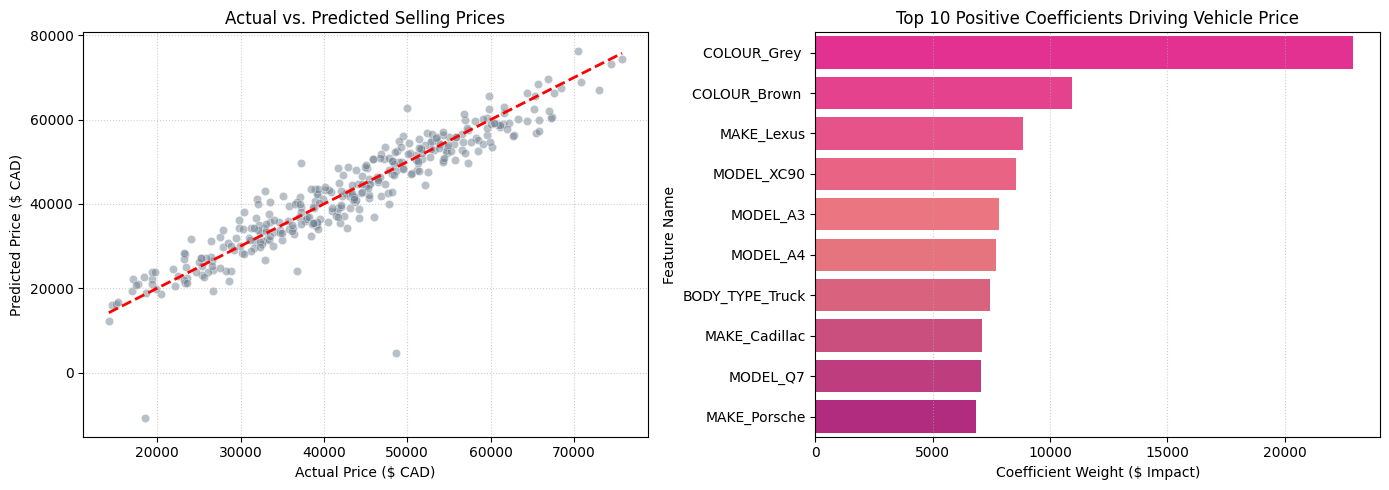

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set up figure for dual evaluation plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot actual vs predicted selling prices using dark slate
sns.scatterplot(x=test_y, y=preds, alpha=0.5, color='slategrey', ax=axes[0])
axes[0].plot([test_y.min(), test_y.max()], [test_y.min(), test_y.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted Selling Prices')
axes[0].set_xlabel('Actual Price ($ CAD)')
axes[0].set_ylabel('Predicted Price ($ CAD)')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Extract top 10 positive price features
top_factors = pd.Series(
    car_eval_model.coef_,
    index=train_features.columns
).sort_values(ascending=False).head(10)

# Custom pink palette for bar chart
pink_coral_palette = sns.color_palette("blend:#ff1493,#ff6b6b,#c71585", n_colors=10)

# Plot top 10 positive linear regression coefficients
sns.barplot(
    x=top_factors.values,
    y=top_factors.index,
    hue=top_factors.index,
    palette=pink_coral_palette,
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Top 10 Positive Coefficients Driving Vehicle Price')
axes[1].set_xlabel('Coefficient Weight ($ Impact)')
axes[1].set_ylabel('Feature Name')
axes[1].grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 5. Optional Model Enhancements (Log Transformation & Ridge Regression)

To see if we can improve baseline linear regression performance and better handle non-linear price curves:
* **Target Log Transformation**: Applied `np.log1p()` to `SELLING_PRICE` to smooth out the right-skewed distribution caused by luxury vehicle outliers.
* **Ridge Regularization**: Fitted a `Ridge(alpha=1.0)` model to reduce potential variance and handle multicollinearity among dummy-encoded categorical variables.
* **Original Dollar Evaluation**: Transformed predicted values back to real dollar amounts using `np.expm1()` to compare MAE, RMSE, and $R^2$ directly against our baseline model.

**Reflection**:
Evaluating predictions back on the actual dollar scale increased MAE from $3,142.74 to $3,765.16 and slightly reduced $R^2$ to 0.8548. Log transforming compressed the target variance, which penalized standard absolute dollar errors when reverted. This confirms that our unscaled baseline Linear Regression model remains the best fit for standard price prediction on this dataset.

In [7]:
from sklearn.linear_model import Ridge
import numpy as np

# Apply log transform to selling price to normalize right-skewed data
log_train_y = np.log1p(train_y)
log_test_y = np.log1p(test_y)

# Train Ridge model to prevent overfitting on dummy variables
model_ridge = Ridge(alpha=1.0)
model_ridge.fit(train_features, log_train_y)

# Get log predictions and convert back to regular dollar amounts
raw_log_preds = model_ridge.predict(test_features)
ridge_predictions = np.expm1(raw_log_preds)

# Calculate evaluation metrics on actual CAD scale
enhanced_mae = mean_absolute_error(test_y, ridge_predictions)
enhanced_rmse = np.sqrt(mean_squared_error(test_y, ridge_predictions))
enhanced_r2 = r2_score(test_y, ridge_predictions)

# Output side-by-side performance comparison
print("--- Baseline Linear Regression vs Ridge Model ---")
print(f"Baseline MAE:  ${mae_score:,.2f} | Baseline RMSE:  ${rmse_score:,.2f} | Baseline R2:  {r2_val:.4f}")
print(f"Enhanced MAE:  ${enhanced_mae:,.2f} | Enhanced RMSE:  ${enhanced_rmse:,.2f} | Enhanced R2:  {enhanced_r2:.4f}")

--- Baseline Linear Regression vs Ridge Model ---
Baseline MAE:  $3,142.74 | Baseline RMSE:  $4,696.32 | Baseline R2:  0.8707
Enhanced MAE:  $3,765.16 | Enhanced RMSE:  $4,975.62 | Enhanced R2:  0.8548
